In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler


In [20]:
# 1. Load
df = pd.read_csv('features.csv')
print(len(df.columns))
# 2. Separate Target and Features
# Target: What we want to predict
Y = df.pivot(index='Date', columns='Store', values='Weekly_Sales').values 
print(f"Target Shape (Time, Nodes): {Y.shape}")
# shape: (143, 45)

# Features: What we use to predict
# We drop 'Date' (index), 'Store' (dimension), and 'Weekly_Sales' (target)
feature_cols = [c for c in df.columns if c not in ['Date', 'Store', 'Weekly_Sales', 'sales_log1p']]

# 3. Scale Features
# GNNs fail if you mix raw dollars (1,000,000) with temperature (40)
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

# 4. Reshape for GNN
# We need a structure of [Time_Steps, Nodes, Features]
# First, sort to ensure alignment
df = df.sort_values(['Date', 'Store'])

# Extract values and reshape
# Total rows = 143 * 45
# Reshape to (143, 45, Num_Features)
num_dates = df['Date'].nunique() # 143
num_stores = df['Store'].nunique() # 45
num_feats = len(feature_cols)

X_all = df[feature_cols].values.reshape(num_dates, num_stores, num_feats)

print(f"Input Shape (Time, Nodes, Features): {X_all.shape}")
# Expected: (143, 45, 34)

38
Target Shape (Time, Nodes): (143, 45)
Input Shape (Time, Nodes, Features): (143, 45, 34)


In [21]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

def create_windowed_dataset(x_data, y_data, window_size=12):
    """
    x_data: (Total_Time, Nodes, Features)
    y_data: (Total_Time, Nodes)
    """
    X_seq, Y_seq = [], []
    # We need 'window_size' steps to predict the next one
    for i in range(len(x_data) - window_size):
        # Input: t to t+12
        X_seq.append(x_data[i : i + window_size])
        # Target: t+12 (The next week)
        Y_seq.append(y_data[i + window_size]) 
        
    return np.array(X_seq), np.array(Y_seq)

# 1. Define Split (Train on first ~80%, Test on last ~20%)
TRAIN_SPLIT = int(143 * 0.8) # 114 weeks
WINDOW_SIZE = 12

# 2. Scale Data (CRITICAL)
# Fit scaler ONLY on training data to avoid leakage
from sklearn.preprocessing import StandardScaler

scaler_x = StandardScaler()
scaler_y = StandardScaler()

# Reshape to 2D for scaling, then back to 3D
X_train = X_all[:TRAIN_SPLIT]
X_test = X_all[TRAIN_SPLIT:]
Y_all = df.pivot(index='Date', columns='Store', values='Weekly_Sales').values
Y_train = Y_all[:TRAIN_SPLIT]
Y_test = Y_all[TRAIN_SPLIT:]

# Scale Inputs
N_train, N_nodes, N_feats = X_train.shape
X_train_scaled = scaler_x.fit_transform(X_train.reshape(-1, N_feats)).reshape(N_train, N_nodes, N_feats)
X_test_scaled = scaler_x.transform(X_test.reshape(-1, N_feats)).reshape(-1, N_nodes, N_feats)

# Scale Targets (Optional but recommended for faster convergence)
Y_train_scaled = scaler_y.fit_transform(Y_train)
Y_test_scaled = scaler_y.transform(Y_test)

# 3. Create Sequences
X_train_win, Y_train_win = create_windowed_dataset(X_train_scaled, Y_train_scaled, WINDOW_SIZE)
X_test_win, Y_test_win = create_windowed_dataset(X_test_scaled, Y_test_scaled, WINDOW_SIZE)

# 4. PyTorch Loaders
# The model expects (Batch, Features, Nodes, Time)
# But we have (Batch, Time, Nodes, Features) -> We must permute
tensor_x_train = torch.FloatTensor(X_train_win).permute(0, 3, 2, 1) 
tensor_y_train = torch.FloatTensor(Y_train_win)

tensor_x_test = torch.FloatTensor(X_test_win).permute(0, 3, 2, 1)
tensor_y_test = torch.FloatTensor(Y_test_win)

train_loader = DataLoader(TensorDataset(tensor_x_train, tensor_y_train), batch_size=32, shuffle=True)
test_loader = DataLoader(TensorDataset(tensor_x_test, tensor_y_test), batch_size=32, shuffle=False)

print(f"Input Batch Shape: {tensor_x_train.shape}") 
# Expected: (Samples, 34, 45, 12) -> (Batch, Feats, Nodes, Time)

Input Batch Shape: torch.Size([102, 34, 45, 12])


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GraphLearner(nn.Module):
    def __init__(self, num_nodes, dim):
        super().__init__()
        # Learnable embeddings for the 45 stores
        self.emb1 = nn.Embedding(num_nodes, dim)
        self.emb2 = nn.Embedding(num_nodes, dim)
        self.lin1 = nn.Linear(dim, dim)
        self.lin2 = nn.Linear(dim, dim)

    def forward(self):
        # Calculate similarity between stores
        nodevec1 = self.lin1(self.emb1.weight)
        nodevec2 = self.lin2(self.emb2.weight)
        # A = ReLU(E1 * E2^T) -> Adjacency Matrix
        adj = F.softmax(F.relu(torch.mm(nodevec1, nodevec2.transpose(0, 1))), dim=1)
        return adj

In [24]:
class TemporalGNN(nn.Module):
    def __init__(self, num_nodes, in_channels, out_channels, window_size):
        super().__init__()
        self.num_nodes = num_nodes
        
        # 1. Graph Learner: Learns relations between the 45 stores
        self.graph_learner = GraphLearner(num_nodes, dim=40)
        
        # 2. Input Projection
        self.start_conv = nn.Conv2d(in_channels, 32, kernel_size=(1,1))
        
        # 3. Temporal Block (Dilated Convolutions)
        # Captures trends like "lag_52" efficiently
        self.tcn = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(1, 3), dilation=1, padding=(0,1)),
            nn.GELU(),
            nn.Conv2d(64, 32, kernel_size=(1, 3), dilation=2, padding=(0,2))
        )
        
        # 4. Graph Convolution (Spatial Block)
        # Aggregates info from correlated stores
        self.gcn_weight = nn.Parameter(torch.randn(32, 32))
        
        # 5. Output Projection
        self.end_conv = nn.Conv2d(32, out_channels, kernel_size=(1,1))
        
    def forward(self, x):
        # x shape: (Batch, Features, Nodes, Time)
        
        # 1. Learn the Graph
        adj = self.graph_learner() # [45, 45]
        
        # 2. Initial Feature Extraction
        x = self.start_conv(x)
        skip = x
        
        # 3. Temporal Processing
        x = self.tcn(x)
        
        # 4. Spatial Processing (Manual GCN implementation for simplicity)
        # AXW operation: Propagate info across the learned graph
        # (Batch, Channels, Nodes, Time) -> Permute for matmul
        B, C, N, T = x.shape
        x_reshape = x.permute(0, 3, 2, 1).reshape(B*T, N, C) 
        # Graph Conv: Adj * X * Weight
        out = torch.matmul(adj, x_reshape) 
        out = torch.matmul(out, self.gcn_weight)
        
        x = out.reshape(B, T, N, C).permute(0, 3, 2, 1) + skip # Residual connection
        
        # 5. Final Prediction
        # We usually take the last time step to predict the future
        x = x[:, :, :, -1:] 
        x = self.end_conv(x)
        return x # Shape: (Batch, 1, 45, 1) -> Prediction for each store

In [25]:
# Hyperparameters
num_nodes = 45
in_channels = X_all.shape[2] # ~34 features
out_channels = 1 # Predicting 1 value (Sales)
window_size = WINDOW_SIZE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = TemporalGNN(num_nodes, in_channels, out_channels, window_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = torch.nn.L1Loss() # MAE is better for Sales than MSE

In [26]:
epochs = 100
train_losses = []
test_losses = []

for epoch in range(epochs):
    # --- Training ---
    model.train()
    batch_loss = []
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        
        optimizer.zero_grad()
        
        # Forward pass
        # Output shape: (Batch, 1, Nodes, 1) -> Squeeze to (Batch, Nodes)
        pred = model(bx).squeeze(-1).squeeze(1)
        
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        
        batch_loss.append(loss.item())
    
    train_avg = np.mean(batch_loss)
    train_losses.append(train_avg)

    # --- Validation ---
    model.eval()
    val_batch_loss = []
    with torch.no_grad():
        for bx, by in test_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx).squeeze(-1).squeeze(1)
            loss = criterion(pred, by)
            val_batch_loss.append(loss.item())
            
    test_avg = np.mean(val_batch_loss)
    test_losses.append(test_avg)
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Train MAE={train_avg:.4f}, Test MAE={test_avg:.4f}")

Epoch 0: Train MAE=0.6676, Test MAE=0.5765
Epoch 10: Train MAE=0.5514, Test MAE=0.5551
Epoch 20: Train MAE=0.4657, Test MAE=0.5477
Epoch 30: Train MAE=0.4815, Test MAE=0.5074
Epoch 40: Train MAE=0.4398, Test MAE=0.4695
Epoch 50: Train MAE=0.3903, Test MAE=0.4534
Epoch 60: Train MAE=0.4152, Test MAE=0.4378
Epoch 70: Train MAE=0.3815, Test MAE=0.4652
Epoch 80: Train MAE=0.3829, Test MAE=0.4413
Epoch 90: Train MAE=0.3855, Test MAE=0.4352


In [27]:
# Get predictions
model.eval()
preds = []
actuals = []

with torch.no_grad():
    for bx, by in test_loader:
        bx = bx.to(device)
        pred = model(bx).squeeze().cpu().numpy()
        preds.append(pred)
        actuals.append(by.numpy())

preds = np.concatenate(preds, axis=0) # Shape: (Test_Samples, 45)
actuals = np.concatenate(actuals, axis=0)

# Inverse Transform to get Real Dollars
# We used scaler_y on the target
preds_dollar = scaler_y.inverse_transform(preds)
actuals_dollar = scaler_y.inverse_transform(actuals)

print("Prediction Example (Store 1, First Test Week):")
print(f"Predicted: ${preds_dollar[0,0]:,.2f}")
print(f"Actual:    ${actuals_dollar[0,0]:,.2f}")

Prediction Example (Store 1, First Test Week):
Predicted: $1,568,586.88
Actual:    $1,769,854.12


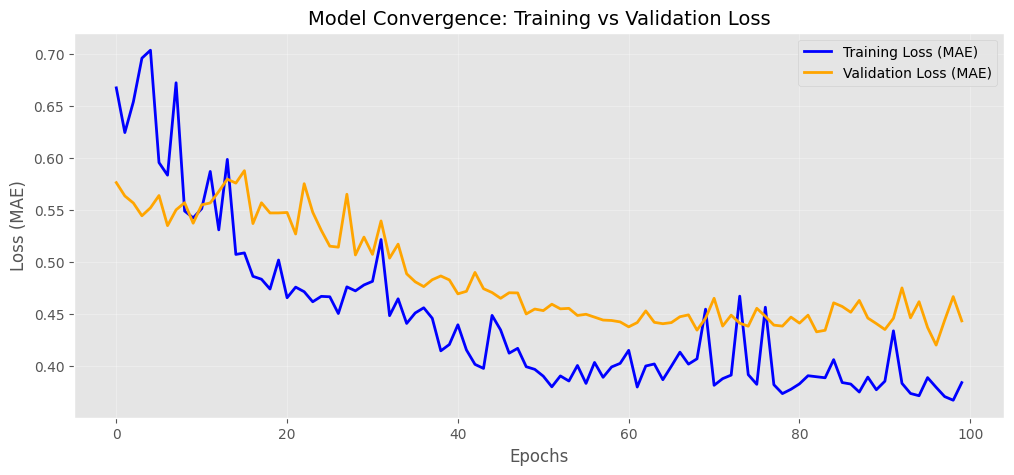

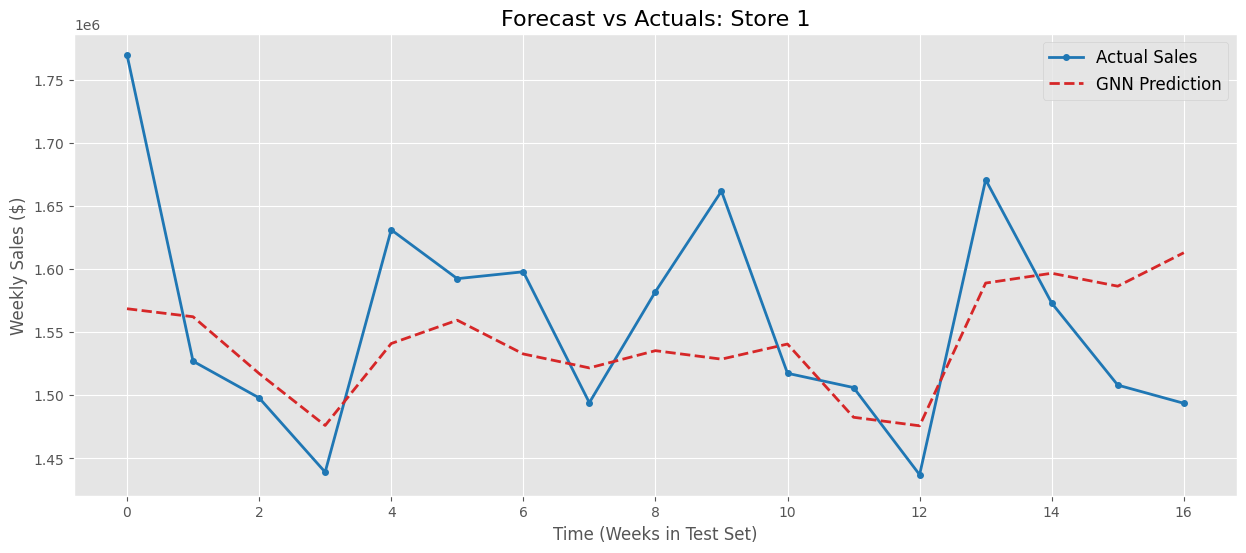

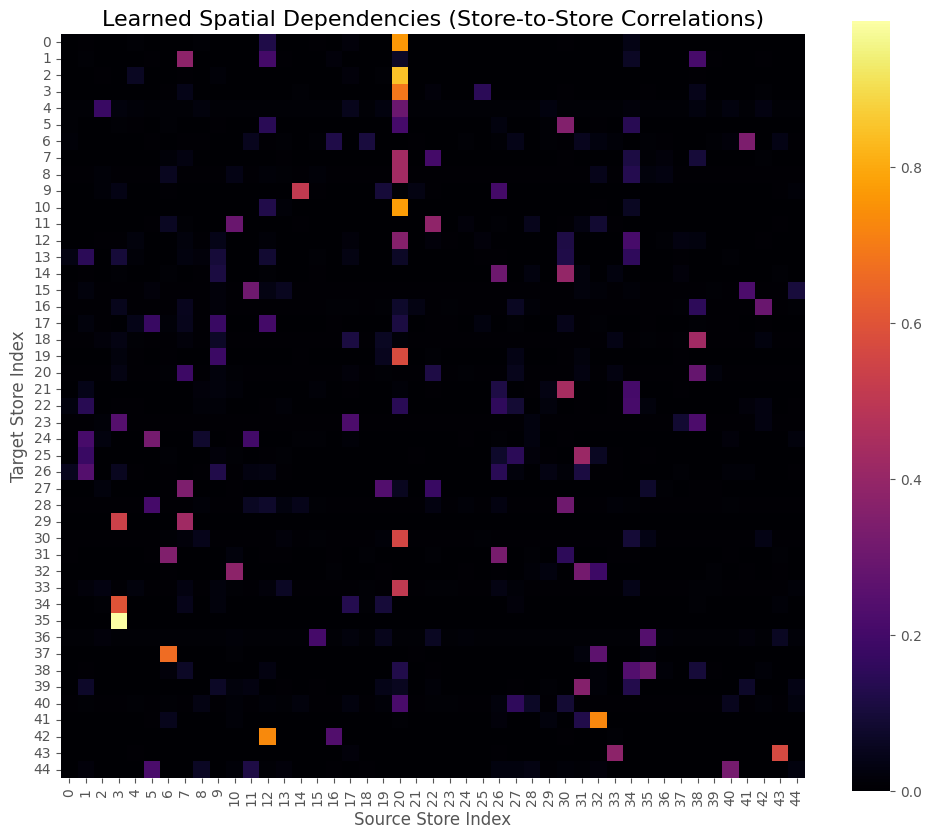

Top 5 Stores influencing Store 1:
- Store 21 (Strength: 0.7608)
- Store 13 (Strength: 0.1208)
- Store 35 (Strength: 0.0379)
- Store 18 (Strength: 0.0178)
- Store 9 (Strength: 0.0115)
- Store 5 (Strength: 0.0088)


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a nice style
plt.style.use('ggplot') 

# ==========================================
# Plot 1: Training vs Validation Loss
# Checks for overfitting and convergence
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(train_losses, label='Training Loss (MAE)', linewidth=2, color='blue')
plt.plot(test_losses, label='Validation Loss (MAE)', linewidth=2, color='orange')
plt.title('Model Convergence: Training vs Validation Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==========================================
# Plot 2: Actual vs Predicted Sales (Specific Store)
# Visually inspect how well the model tracks trends
# ==========================================
store_idx = 0  # Change this (0-44) to see different stores
subset_len = 50 # View last 50 weeks for clarity

plt.figure(figsize=(15, 6))
plt.plot(actuals_dollar[-subset_len:, store_idx], label='Actual Sales', marker='o', markersize=4, linewidth=2, color='tab:blue')
plt.plot(preds_dollar[-subset_len:, store_idx], label='GNN Prediction', linestyle='--', linewidth=2, color='tab:red')
plt.title(f'Forecast vs Actuals: Store {store_idx+1}', fontsize=16)
plt.xlabel('Time (Weeks in Test Set)')
plt.ylabel('Weekly Sales ($)')
plt.legend(fontsize=12)
plt.show()

# ==========================================
# Plot 3: The "Brain" of the GNN (Adjacency Matrix)
# Shows which stores the model learned are correlated
# ==========================================
model.eval()
# Extract the learned matrix from the GraphLearner module
adj_matrix = model.graph_learner().detach().cpu().numpy()

plt.figure(figsize=(12, 10))
sns.heatmap(adj_matrix, cmap='inferno', square=True, vmin=0, vmax=np.max(adj_matrix))
plt.title('Learned Spatial Dependencies (Store-to-Store Correlations)', fontsize=16)
plt.xlabel('Source Store Index')
plt.ylabel('Target Store Index')
plt.show()

# ==========================================
# Bonus: Top Correlations
# Find out which stores influence Store 1 the most
# ==========================================
target_store = 0
correlations = adj_matrix[target_store]
# Get top 5 influencing stores (excluding itself)
top_indices = correlations.argsort()[-6:][::-1] # Top 6 (including self)

print(f"Top 5 Stores influencing Store {target_store+1}:")
for idx in top_indices:
    if idx != target_store:
        print(f"- Store {idx+1} (Strength: {correlations[idx]:.4f})")

In [29]:
import pandas as pd
import numpy as np

# 1. Initialize list to store metrics
metrics_list = []

# 2. Loop through each store (0 to 44)
num_stores = actuals_dollar.shape[1]

for i in range(num_stores):
    act = actuals_dollar[:, i]
    pred = preds_dollar[:, i]
    
    # Calculate Metrics
    mae = np.mean(np.abs(pred - act))
    rmse = np.sqrt(np.mean((pred - act)**2))
    # Add small epsilon (1e-6) to avoid division by zero error
    mape = np.mean(np.abs((act - pred) / (act + 1e-6))) * 100
    
    metrics_list.append({
        'Store': i + 1,
        'MAE ($)': mae,
        'RMSE ($)': rmse,
        'MAPE (%)': mape
    })

# 3. Convert to DataFrame for nice formatting
results_df = pd.DataFrame(metrics_list)

# 4. Sort by Accuracy (Lowest MAPE is best)
results_df = results_df.sort_values('MAPE (%)')

# 5. Print the Table
print("="*60)
print("STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)")
print("="*60)
# Format floats to 2 decimal places with commas for dollars
print(results_df.to_string(index=False, float_format=lambda x: "{:,.2f}".format(x)))
print("="*60)

# 6. Print Summary Highlights
best_store = results_df.iloc[0]
worst_store = results_df.iloc[-1]

print(f"\nBest Performing:  Store {int(best_store['Store'])} (MAPE: {best_store['MAPE (%)']:.2f}%)")
print(f"Worst Performing: Store {int(worst_store['Store'])} (MAPE: {worst_store['MAPE (%)']:.2f}%)")

STORE-WISE PERFORMANCE METRICS (Sorted by Accuracy)
 Store    MAE ($)   RMSE ($)  MAPE (%)
    37   9,955.40  11,929.79      1.90
    34  25,835.37  31,120.55      2.67
    20  65,042.36  88,763.09      3.12
    13  64,666.64  79,631.97      3.13
     3  13,348.71  17,028.29      3.21
     4  74,547.40  86,270.27      3.45
    43  21,706.48  26,361.23      3.46
    32  41,971.68  59,037.84      3.47
    45  26,024.81  31,298.46      3.49
    22  35,308.35  42,593.58      3.50
     8  34,077.47  42,394.13      3.68
    30  16,061.47  18,425.56      3.69
     5  12,151.98  15,336.81      3.70
    31  50,910.43  63,690.39      3.77
    27  66,929.95 100,052.66      3.77
     9  20,777.73  23,368.63      3.78
    12  38,381.11  52,931.55      3.85
     1  63,356.35  79,644.96      3.96
     2  79,040.09  97,595.34      4.13
     6  77,787.86 103,868.49      4.88
    40  50,959.01  72,029.20      4.89
    11  66,653.85  86,501.24      5.12
    23  78,862.04 112,694.47      5.25
    15  30,7